In [3]:
# chargement des librairies
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# chargement du dataset. Nous utilisons la date comme index de navigation
df = pd.read_csv('../../datasets/processed/dec2008-june2017/processed-weather-aus-dec2008-june2017.csv', index_col="Date")
# affichage du dataset
df

,mintemp,maxtemp,rainfall,windgustspeed,windspeed9am,windspeed3pm,humidity9am,humidity3pm,pressure9am,pressure3pm,...,winddir3pm_S,winddir3pm_SE,winddir3pm_SSE,winddir3pm_SSW,winddir3pm_SW,winddir3pm_W,winddir3pm_WNW,winddir3pm_WSW,raintoday_No,raintoday_Yes
Date,,,,,,,,,,,,,,,,,,,,,
2008-12-01,13.4,22.9,0.6,44.0,20.0,24.0,71.0,22.0,1007.7,1007.1,...,False,False,False,False,False,False,True,False,True,False
2008-12-02,7.4,25.1,0.0,44.0,4.0,22.0,44.0,25.0,1010.6,1007.8,...,False,False,False,False,False,False,False,True,True,False
2008-12-03,12.9,25.7,0.0,46.0,19.0,26.0,38.0,30.0,1007.6,1008.7,...,False,False,False,False,False,False,False,True,True,False
2008-12-04,9.2,28.0,0.0,24.0,11.0,9.0,45.0,16.0,1017.6,1012.8,...,False,False,False,False,False,False,False,False,True,False
2008-12-05,17.5,32.3,1.0,41.0,7.0,20.0,82.0,33.0,1010.8,1006.0,...,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-06-20,3.5,21.8,0.0,31.0,15.0,13.0,59.0,27.0,1024.7,1021.2,...,False,False,False,False,False,False,False,False,True,False
2017-06-21,2.8,23.4,0.0,31.0,13.0,11.0,51.0,24.0,1024.6,1020.3,...,False,False,False,False,False,False,False,False,True,False
2017-06-22,3.6,25.3,0.0,22.0,13.0,9.0,56.0,21.0,1023.5,1019.1,...,False,False,False,False,False,False,False,False,True,False


In [5]:
# description breve du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 112925 entries, 2008-12-01 to 2017-06-24
Columns: 107 entries, mintemp to raintoday_Yes
dtypes: bool(94), float64(12), int64(1)
memory usage: 22.2+ MB


In [6]:
# extraction des variables prédictives
X = df.drop(['raintomorrow'], axis = 1)
# extraction de la variable réponse
Y = df['raintomorrow']

In [7]:
# chargement de quelques modules de machine learning
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from mlxtend.plotting import plot_confusion_matrix
from joblib import dump, load
import pickle
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
#from sklearn.tree import DecisionTreeClassifier
#from sklearn.neighbors import KNeighborsClassifier

In [8]:
# création des datasets d'entrainement et de test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, stratify = Y, test_size = 0.3, random_state=42)
# dimensions des datasets créés
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((79047, 106), (33878, 106), (79047,), (33878,))

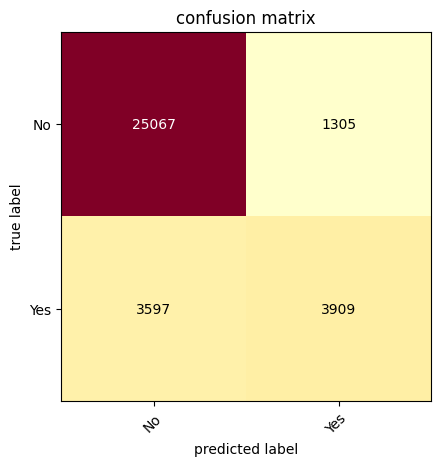

              precision    recall  f1-score   support

           0       0.87      0.95      0.91     26372
           1       0.75      0.52      0.61      7506

    accuracy                           0.86     33878
   macro avg       0.81      0.74      0.76     33878
weighted avg       0.85      0.86      0.85     33878



In [9]:
# Logistic Regression
pipe_lr = Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression())])
pipe_lr.fit(X_train,Y_train)
predictions = pipe_lr.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

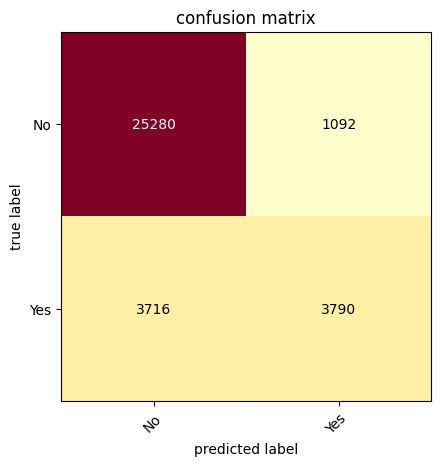

              precision    recall  f1-score   support

           0       0.87      0.96      0.91     26372
           1       0.78      0.50      0.61      7506

    accuracy                           0.86     33878
   macro avg       0.82      0.73      0.76     33878
weighted avg       0.85      0.86      0.85     33878



In [10]:
# Random Forest
pipe_rf = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier())])
pipe_rf.fit(X_train,Y_train)
predictions = pipe_rf.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

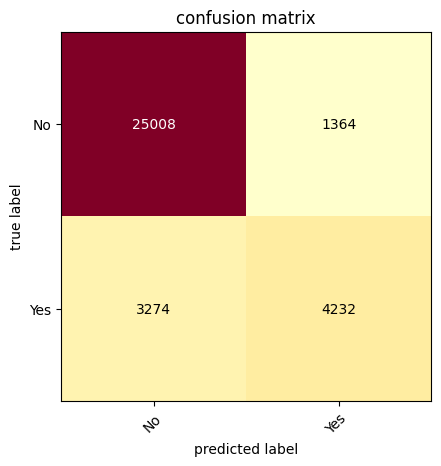

              precision    recall  f1-score   support

           0       0.88      0.95      0.92     26372
           1       0.76      0.56      0.65      7506

    accuracy                           0.86     33878
   macro avg       0.82      0.76      0.78     33878
weighted avg       0.86      0.86      0.86     33878



In [11]:
# XGBoost
pipe_xgb = Pipeline([('scaler', StandardScaler()), ('xgb', XGBClassifier())])
pipe_xgb.fit(X_train,Y_train)
predictions = pipe_xgb.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

In [12]:
# équilibrage des classes sur les  données d'entrainement
smote = SMOTE(random_state=42)
X_train_smote, Y_train_smote = smote.fit_resample(X_train, Y_train)
X_train_smote.shape, Y_train_smote.shape

((123068, 106), (123068,))

/home/pdkengne/Documents/DataScientest/projet-meteo-1/MAR23CMLOPS_meteo/projet_meteo_env/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


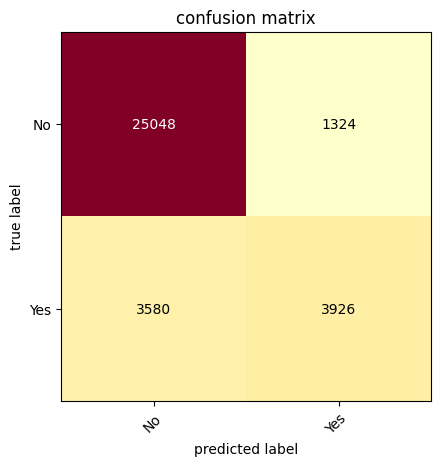

              precision    recall  f1-score   support

           0       0.87      0.95      0.91     26372
           1       0.75      0.52      0.62      7506

    accuracy                           0.86     33878
   macro avg       0.81      0.74      0.76     33878
weighted avg       0.85      0.86      0.85     33878



In [13]:
# Logistic Regression
pipe_lr = Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression())])
pipe_lr.fit(X_train_smote,Y_train_smote)
predictions = pipe_lr.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

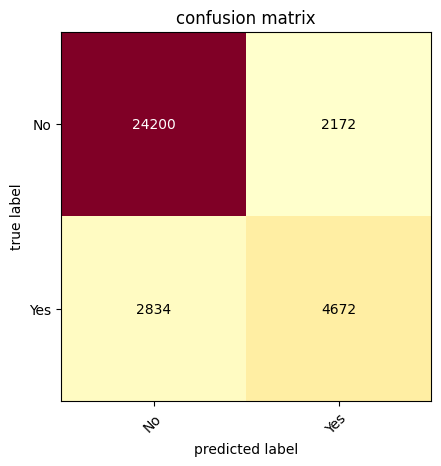

              precision    recall  f1-score   support

           0       0.90      0.92      0.91     26372
           1       0.68      0.62      0.65      7506

    accuracy                           0.85     33878
   macro avg       0.79      0.77      0.78     33878
weighted avg       0.85      0.85      0.85     33878



In [14]:
# Random Forest
pipe_rf = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier())])
pipe_rf.fit(X_train_smote,Y_train_smote)
predictions = pipe_rf.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

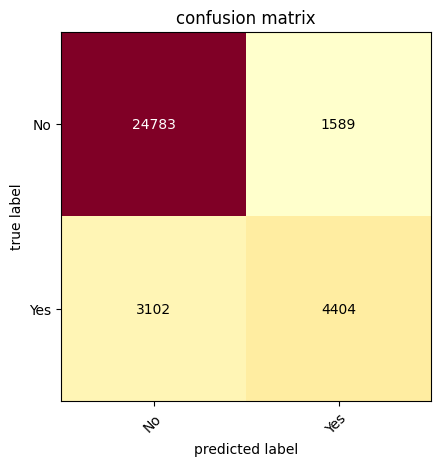

              precision    recall  f1-score   support

           0       0.89      0.94      0.91     26372
           1       0.73      0.59      0.65      7506

    accuracy                           0.86     33878
   macro avg       0.81      0.76      0.78     33878
weighted avg       0.85      0.86      0.86     33878



In [15]:
# XGBoost
pipe_xgb = Pipeline([('scaler', StandardScaler()), ('xgb', XGBClassifier())])
pipe_xgb.fit(X_train_smote,Y_train_smote)
predictions = pipe_xgb.predict(X_test)
cm=confusion_matrix(Y_test, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_test, predictions))
# print(accuracy_score(Y_test, predictions))

In [ ]:
# Note: les deux meilleurs modèles sont: random forest et xgboost obtenus après suréchantillonnage de la classe minoritaire des données d'entrainement

In [ ]:
# entrainement des deux meilleurs modèles sur le dataset entier

In [16]:
# création des datasets d'entrainement et de test
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.000001, random_state=42)
# dimensions des datasets créés
X_train.shape, X_test.shape, Y_train.shape, Y_test.shape

((112924, 106), (1, 106), (112924,), (1,))

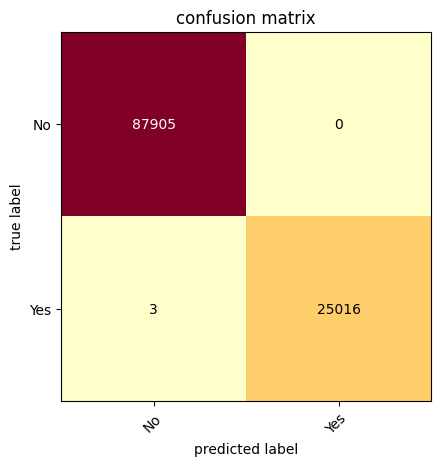

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     87905
           1       1.00      1.00      1.00     25019

    accuracy                           1.00    112924
   macro avg       1.00      1.00      1.00    112924
weighted avg       1.00      1.00      1.00    112924



In [17]:
# Random Forest
pipe_rf = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier())])
pipe_rf.fit(X_train,Y_train)
predictions = pipe_rf.predict(X_train)
cm=confusion_matrix(Y_train, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_train, predictions))
# print(accuracy_score(Y_train, predictions))

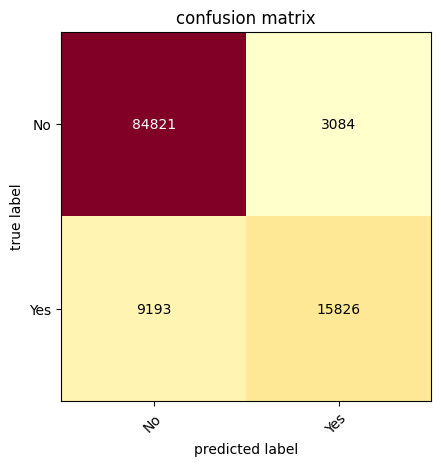

              precision    recall  f1-score   support

           0       0.90      0.96      0.93     87905
           1       0.84      0.63      0.72     25019

    accuracy                           0.89    112924
   macro avg       0.87      0.80      0.83    112924
weighted avg       0.89      0.89      0.89    112924



In [18]:
# XGBoost
pipe_xgb = Pipeline([('scaler', StandardScaler()), ('xgb', XGBClassifier())])
pipe_xgb.fit(X_train,Y_train)
predictions = pipe_xgb.predict(X_train)
cm=confusion_matrix(Y_train, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_train, predictions))
# print(accuracy_score(Y_train, predictions))

In [19]:
# équilibrage des classes sur les  données d'entrainement
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, Y_train_smote = smote.fit_resample(X_train, Y_train)
X_train_smote.shape, Y_train_smote.shape

((175810, 106), (175810,))

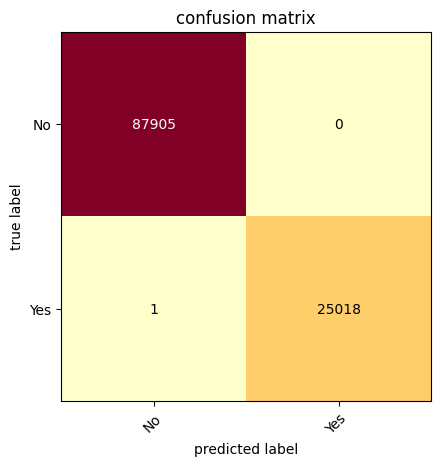

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     87905
           1       1.00      1.00      1.00     25019

    accuracy                           1.00    112924
   macro avg       1.00      1.00      1.00    112924
weighted avg       1.00      1.00      1.00    112924



In [20]:
# Random Forest
pipe_rf = Pipeline([('scaler', StandardScaler()), ('rf', RandomForestClassifier())])
pipe_rf.fit(X_train_smote,Y_train_smote)
predictions = pipe_rf.predict(X_train)
cm=confusion_matrix(Y_train, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_train, predictions))
# print(accuracy_score(Y_train, predictions))

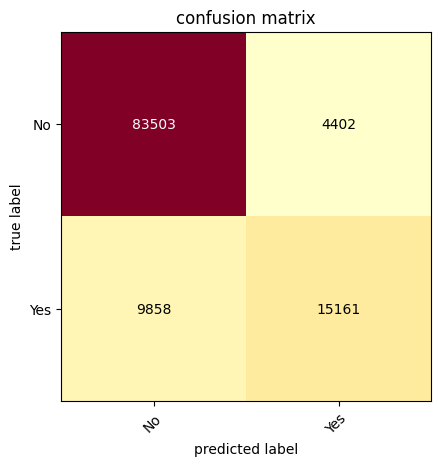

              precision    recall  f1-score   support

           0       0.89      0.95      0.92     87905
           1       0.77      0.61      0.68     25019

    accuracy                           0.87    112924
   macro avg       0.83      0.78      0.80    112924
weighted avg       0.87      0.87      0.87    112924



In [21]:
# XGBoost
pipe_xgb = Pipeline([('scaler', StandardScaler()), ('xgb', XGBClassifier())])
pipe_xgb.fit(X_train_smote,Y_train_smote)
predictions = pipe_xgb.predict(X_train)
cm=confusion_matrix(Y_train, predictions)
plot_confusion_matrix(cm , class_names=["No","Yes"], cmap='YlOrRd')
plt.title('confusion matrix')
plt.show()
print(classification_report(Y_train, predictions))
# print(accuracy_score(Y_train, predictions))

In [ ]:
# le modèle basé sur les forêts aléatoires semble être le meilleur sur tout le dataset d'entrainement

In [28]:
# sauvegarde du modèle meilleur sélectionné
#pickle.dump(pipe_rf, open('../../models/final_model_pipe_rf_v1.pkl', 'wb'))

In [ ]:
# utilisation du modèle chargé
#pickled_model = pickle.load(open('../../models/final_model_pipe_rf_v1.pkl', 'rb'))
#pickled_model.predict(X_test)